In [151]:
#from core.config import DB_PATH
from matplotlib import pyplot as plt
import pandas as pd
import sqlite3 as sql
import seaborn as sns

plt.rcParams["figure.figsize"]=(12.8, 7.2)

In [160]:
with sql.connect("C:\\Users\\marki\\PycharmProjects\\pokemon_ds\\data\\pokemon.db") as conn:
    pokemon = pd.read_sql("SELECT * FROM pokemons", conn)
    species = pd.read_sql("SELECT * FROM species", conn)

In [161]:
pokemon = pokemon.iloc[:, :-1]
pokemon["base_experience"] = pokemon["base_experience"].astype("Int64")

species = species.set_index("id")

df = pd.merge(pokemon, species, left_on="species_id", right_on="id", how="left")
df = df.rename(columns={
    'name_x': 'name',   
    'name_y': 'species'     
})

stats = ["hp", "attack", "defense", "special_attack", "special_defense", "speed", "total_stats"]

In [87]:
pokemon

,id,name,height,weight,hp,attack,defense,special_attack,special_defense,speed,total_stats,base_experience,types,primary_type,abilities,hidden_abilities,is_default,species_id
0,1,bulbasaur,70,6.9,45,49,49,65,65,45,318,64,"grass, poison",grass,overgrow,chlorophyll,1,1
1,2,ivysaur,100,13.0,60,62,63,80,80,60,405,142,"grass, poison",grass,overgrow,chlorophyll,1,2
2,3,venusaur,200,100.0,80,82,83,100,100,80,525,236,"grass, poison",grass,overgrow,chlorophyll,1,3
3,4,charmander,60,8.5,39,52,43,60,50,65,309,62,fire,fire,blaze,solar-power,1,4
4,5,charmeleon,110,19.0,58,64,58,80,65,80,405,142,fire,fire,blaze,solar-power,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1346,10322,tatsugiri-curly-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1347,10323,tatsugiri-droopy-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1348,10324,tatsugiri-stretchy-mega,60,24.0,68,65,90,135,125,92,575,<NA>,"dragon, water",dragon,,NaN,0,978
1349,10325,baxcalibur-mega,210,315.0,115,175,117,105,101,87,700,<NA>,"dragon, ice",dragon,thermal-exchange,NaN,0,998


In [88]:
species

,name,gender_rate,capture_rate,base_happiness,is_baby,is_legendary,is_mythical,generation
id,,,,,,,,
1,bulbasaur,1,45,70,0,0,0,1
2,ivysaur,1,45,70,0,0,0,1
3,venusaur,1,45,70,0,0,0,1
4,charmander,1,45,70,0,0,0,1
5,charmeleon,1,45,70,0,0,0,1
...,...,...,...,...,...,...,...,...
1021,raging-bolt,-1,10,0,0,0,0,9
1022,iron-boulder,-1,10,0,0,0,0,9
1023,iron-crown,-1,10,0,0,0,0,9


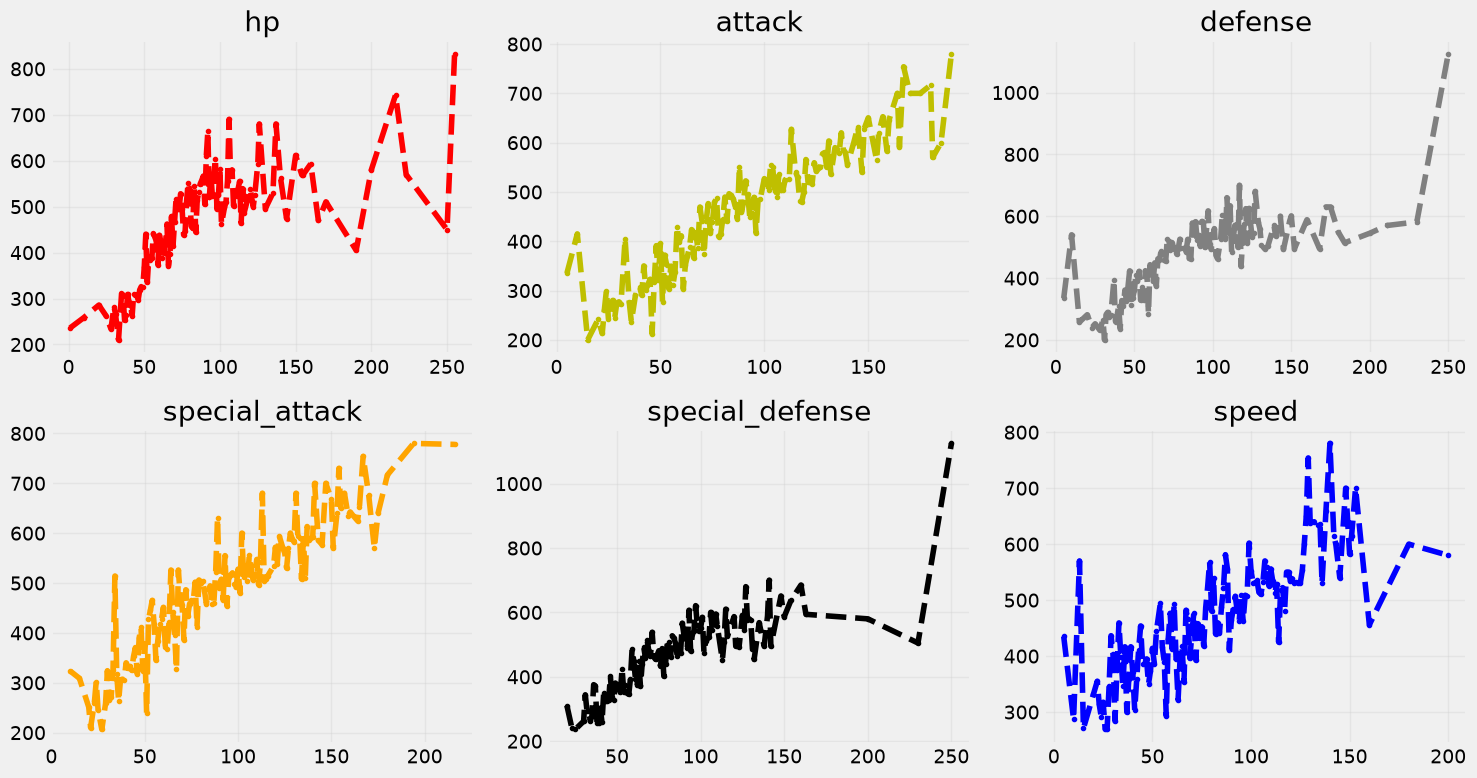

In [116]:
stats = ["hp", "attack", "defense", "special_attack", "special_defense", "speed", "total_stats"]
colors = ["r", "y", "grey", "orange", "k", "b"]
plot_data = df[stats].dropna()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, stat, color in zip(axes, stats, colors):
    grouped = plot_data.groupby(stat, as_index=False)["total_stats"].mean()
    ax.plot(grouped[stat], grouped["total_stats"],
            linestyle='--', marker='.', color=color)
    ax.set_title(stat)
    ax.grid(True, alpha=0.3)

plt.style.use("fivethirtyeight")
plt.tight_layout()
plt.show()

In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1351 non-null   int64  
 1   name              1351 non-null   str    
 2   height            1351 non-null   int64  
 3   weight            1351 non-null   float64
 4   hp                1351 non-null   int64  
 5   attack            1351 non-null   int64  
 6   defense           1351 non-null   int64  
 7   special_attack    1351 non-null   int64  
 8   special_defense   1351 non-null   int64  
 9   speed             1351 non-null   int64  
 10  total_stats       1351 non-null   int64  
 11  base_experience   1302 non-null   Int64  
 12  types             1351 non-null   str    
 13  primary_type      1351 non-null   str    
 14  abilities         1351 non-null   str    
 15  hidden_abilities  988 non-null    str    
 16  is_default        1351 non-null   int64  
 17  specie

In [142]:
df.duplicated().sum()

np.int64(0)

In [90]:
missing_cols = df.isna().sum()
missing_cols[missing_cols > 0]

base_experience      49
hidden_abilities    363
dtype: int64

In [ ]:
base_exp_missing = df[df["base_experience"].isna()]
mega_pokemon = df[df["name"].str.find("-mega") != -1]
print(base_exp_missing.shape[0])
print(base_exp_missing[base_exp_missing["hidden_abilities"].isna()].shape[0])

49
49


In [136]:
styles = [
    # Color the left table's body (even columns: col0, col2, col4)
    {'selector': 'td.col0, td.col2, td.col4', 'props': 'background-color: #d4e6f1; color: black;'},
    # Color the right table's body (odd columns: col1, col3, col5)
    {'selector': 'td.col1, td.col3, td.col5', 'props': 'background-color: #fadbd8; color: black;'},
    
    # Match the top headers to the body colors
    {'selector': 'th.col_heading.level0.col0', 'props': 'background-color: #d4e6f1; color: black;'},
    {'selector': 'th.col_heading.level0.col3', 'props': 'background-color: #fadbd8; color: black;'},
    {'selector': 'th.col_heading.level0', 'props': 'text-align: center; font-weight: bold; border-bottom: 2px solid black;'},
    
    # Add a thick visual separator down the middle
    {'selector': 'th.col_heading.level0.col3', 'props': 'border-left: 3px solid black;'},
    {'selector': 'td.col3', 'props': 'border-left: 3px solid black;'}
]

pd.concat([mega_pokemon[["height", "weight", "total_stats"]].describe(), pokemon[["height", "weight", "total_stats"]].describe()], axis=1, keys=["mega_pokemon", "other_pokemon"]).style.set_table_styles(styles).set_caption("Comparison of Mega Pokémon vs Other Pokémon").format("{:.2f}")

In [154]:
df[stats].describe().T

,count,mean,std,min,25%,50%,75%,max
hp,1351.0,71.673575,26.827529,1.0,55.0,70.0,85.0,255.0
attack,1351.0,82.757957,32.351906,5.0,60.0,80.0,102.5,190.0
defense,1351.0,76.193930,30.712902,5.0,55.0,70.0,95.0,250.0
special_attack,1351.0,75.418209,34.026272,10.0,50.0,69.0,97.0,216.0
special_defense,1351.0,74.115470,27.800826,20.0,54.0,70.0,90.0,250.0
speed,1351.0,72.000000,30.642043,5.0,49.0,70.0,95.0,200.0
total_stats,1351.0,452.159141,122.456241,175.0,340.0,475.0,530.0,1125.0


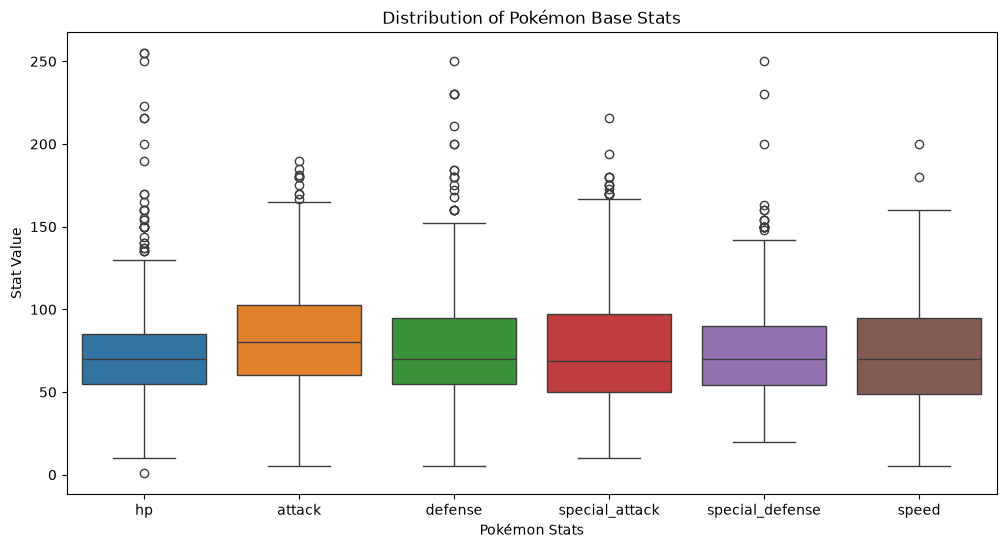

In [157]:
st = ["hp", "attack", "defense", "special_attack", "special_defense", "speed"]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[st])

plt.title("Distribution of Pokémon Base Stats")
plt.ylabel("Stat Value")
plt.xlabel("Pokémon Stats")

plt.show()

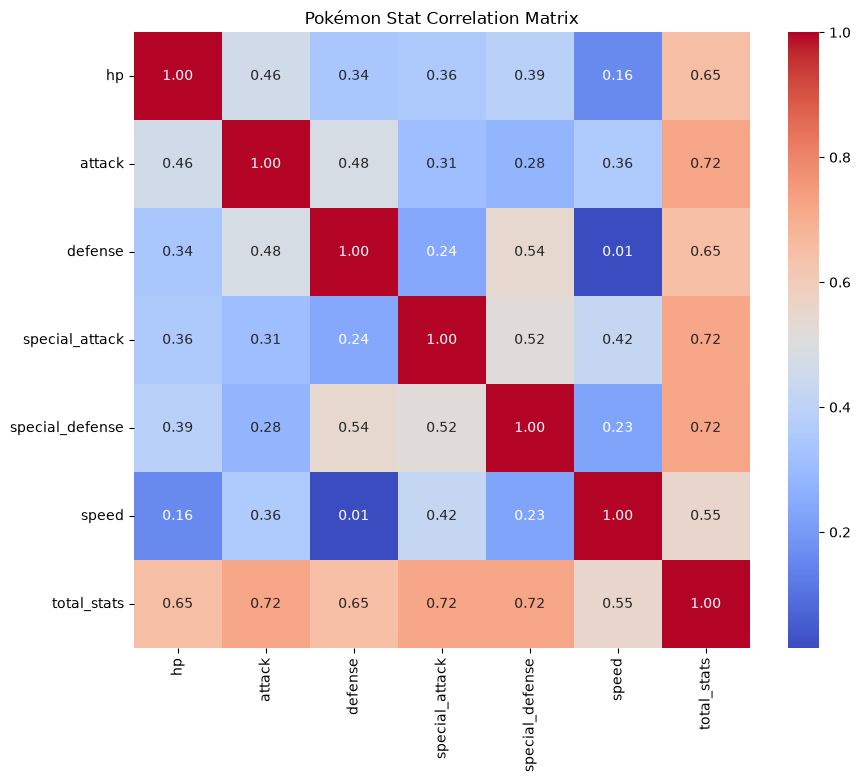

In [166]:
correlation = df[stats].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Pokémon Stat Correlation Matrix")

plt.show()

In [204]:
df.sort_values(by="total_stats", ascending=False).head(5)

,id,name,height,weight,hp,attack,defense,special_attack,special_defense,speed,...,is_default,species_id,species,gender_rate,capture_rate,base_happiness,is_baby,is_legendary,is_mythical,generation
1214,10190,eternatus-eternamax,10000,0.0,255,115,250,125,250,130,...,0,890,eternatus,-1,255,0,0,1,0,8
1068,10044,mewtwo-mega-y,150,33.0,106,150,70,194,120,140,...,0,150,mewtwo,-1,3,0,0,1,0,1
1067,10043,mewtwo-mega-x,230,127.0,106,190,100,154,100,130,...,0,150,mewtwo,-1,3,0,0,1,0,1
1103,10079,rayquaza-mega,1080,392.0,105,180,100,180,100,115,...,0,384,rayquaza,-1,45,0,0,1,0,3
1325,10301,zygarde-mega,770,610.0,216,70,91,216,85,100,...,0,718,zygarde,-1,3,0,0,1,0,6


In [ ]:
df.groupby("primary_type")["total_stats"].mean().sort_values(ascending=False)

primary_type
dragon      544.728814
steel       504.711538
psychic     489.325581
fighting    486.241935
fire        468.023810
fairy       463.028571
dark        462.571429
flying      457.692308
rock        456.819277
ground      449.460000
electric    446.600000
ghost       445.134615
poison      443.923077
water       443.375000
ice         441.840909
grass       435.459016
normal      413.942446
bug         392.810526
Name: total_stats, dtype: float64


In [198]:
legends = df.groupby("is_legendary")[stats].mean()
legends.index = legends.index.map({1: "Legendary", 0: "Non-Legendary"})

megas = mega_pokemon[stats].mean().rename("Mega")
others = df[(~df['name'].isin(mega_pokemon['name'])) & (df['is_legendary'] == False)][stats].mean().rename("Other (Non-Legendary, Non-Mega)")

combined = pd.concat([legends, megas.to_frame().T, others.to_frame().T])
combined.round(2)

,hp,attack,defense,special_attack,special_defense,speed,total_stats
Non-Legendary,69.00,80.05,73.83,72.15,71.28,69.26,435.57
Legendary,99.08,110.52,100.46,108.98,103.18,100.12,622.34
Mega,79.74,119.97,103.78,117.70,102.13,94.29,617.62
"Other (Non-Legendary, Non-Mega)",68.35,76.99,71.43,68.90,68.94,67.38,421.99


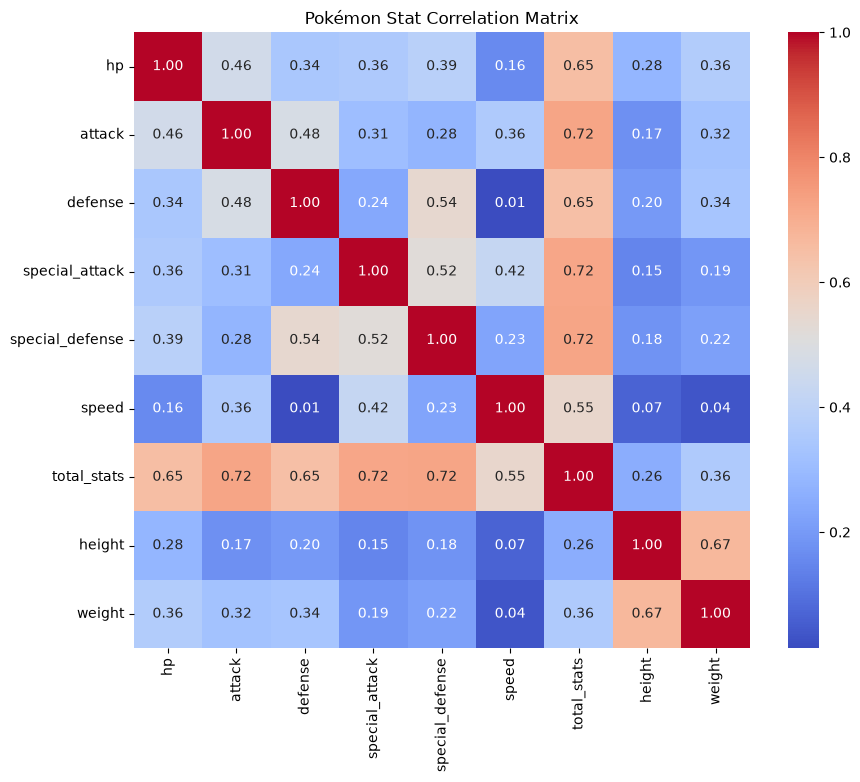

In [199]:
correlation = df[stats + ["height", "weight"]].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Pokémon Stat Correlation Matrix")

plt.show()

In [212]:
df.groupby("primary_type").agg({'id': 'count', 'total_stats': 'mean', 'is_legendary': lambda x: x.sum() / x.count() * 100}).sort_values(by='total_stats', ascending=False).rename(columns={'id': 'count', 'total_stats': 'avg_total_stats', 'is_legendary': 'legendary_percentage'})

,count,avg_total_stats,legendary_percentage
primary_type,,,
dragon,59,544.728814,30.508475
steel,52,504.711538,7.692308
psychic,86,489.325581,24.418605
fighting,62,486.241935,20.967742
fire,84,468.023810,5.952381
fairy,35,463.028571,14.285714
dark,63,462.571429,9.523810
flying,13,457.692308,15.384615
rock,83,456.819277,2.409639


In [224]:
df[(df['is_legendary'] == False) & (df['is_mythical'] == False)].groupby("primary_type").agg({'id': 'count', 'total_stats': 'mean'}).sort_values(by='total_stats', ascending=False).rename(columns={'id': 'count', 'total_stats': 'avg_total_stats'})

,count,avg_total_stats
primary_type,,
dragon,41,498.073171
steel,40,475.625000
fire,78,456.076923
fighting,48,451.500000
rock,79,448.810127
dark,53,435.886792
flying,11,435.454545
fairy,30,433.533333
ghost,49,432.795918
